## Experiment

In [1]:
import os
for k,v in os.environ.items():
    if k.startswith("QUANTDATA_"):
        print(f"{k}={v}")
        

QUANTDATA_EXPERIMENTS=/media/storage/quantdata/experiments
QUANTDATA_PROCESSING_DATA=/media/storage/quantdata/processing
QUANTDATA_RAW_DATA=/mnt/aae/quantdata
QUANTDATA_TRAINING_DATA=/media/storage/quantdata/training


In [2]:

%load_ext autoreload
%autoreload 1

%aimport quantdata.dysanos.grid.torch_market
%aimport quantdata.dysanos.grid.torch_pricer
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 
%aimport quantdata.dysanos.grid.torch_simulator
%aimport quantdata.dysanos.grid.torch_universe
%aimport quantdata.dysanos.grid.torch_det_measure_change
%aimport quantdata.dysanos.grid.torch_all
%aimport quantdata.dysanos.grid.torch_drift_changeV2

from quantdata.dysanos.grid.torch_all import run_experiment_tight, DysanosExperiment, PrettyObject
import gc
gc.collect()

experiment_config = DysanosExperiment(num_samples=100_000)

ex = run_experiment_tight(
    experiment_config,
    plot_sampler=True,
    plot_det_measure_change=True)
ex = PrettyObject(ex)

print("*** READY ***")

*** READY ***


0.0 GiB allocated
0.0 GiB reserved

***Allocated CUDA device cuda:2 with lock file /tmp/locks/quant_data/torch/cuda_2.lck.
00: Training drn,outer,cost=std,u=pexp,rndboot,delthdg,batched_v2 version 0.51 group 'dysanosV2' for 200000 epochs.
00: Using batches of 20000 samples with learning rate 0.001 and weight decay 0.0001.
00: Instantiating drn,outer,cost=std,u=pexp,rndboot,delthdg,batched_v2 version 0.51 on Env(prec=32,device=cuda:2,debug=False)... done; this took 0.12s.
00: Found existing recovery checkpoint '/home/hans/.dysanos_dhx/dysanosV2/drn,outer,cost=std,u=pexp,rndboot,delth 0e18ff81.pt'. Restoring model state from this checkpoint.
00: Copying spots of size 3906.25KB to Env(prec=32,device=cuda:2,debug=False) which brings total GPU memory use to 484.47MB... 

/home/hans/python/quant_data/quantdata/dysanos/grid/torch_drift_changeV2.py:1561: UserWarning: Checkpoint '/home/hans/.dysanos_dhx/dysanosV2/drn,outer,cost=std,u=pexp,rndboot,delth 0e18ff81.pt' file user_version 0.5 does not match model user_version 0.51. -- Restarting training.


00: Copied 7 arrays with a total size 2070.62MB to Env(prec=32,device=cuda:2,debug=False). This took 0.82s.                          
00: Initial training loss is -0.0002356 and validation loss -2.789e-05. This took 0.44s.


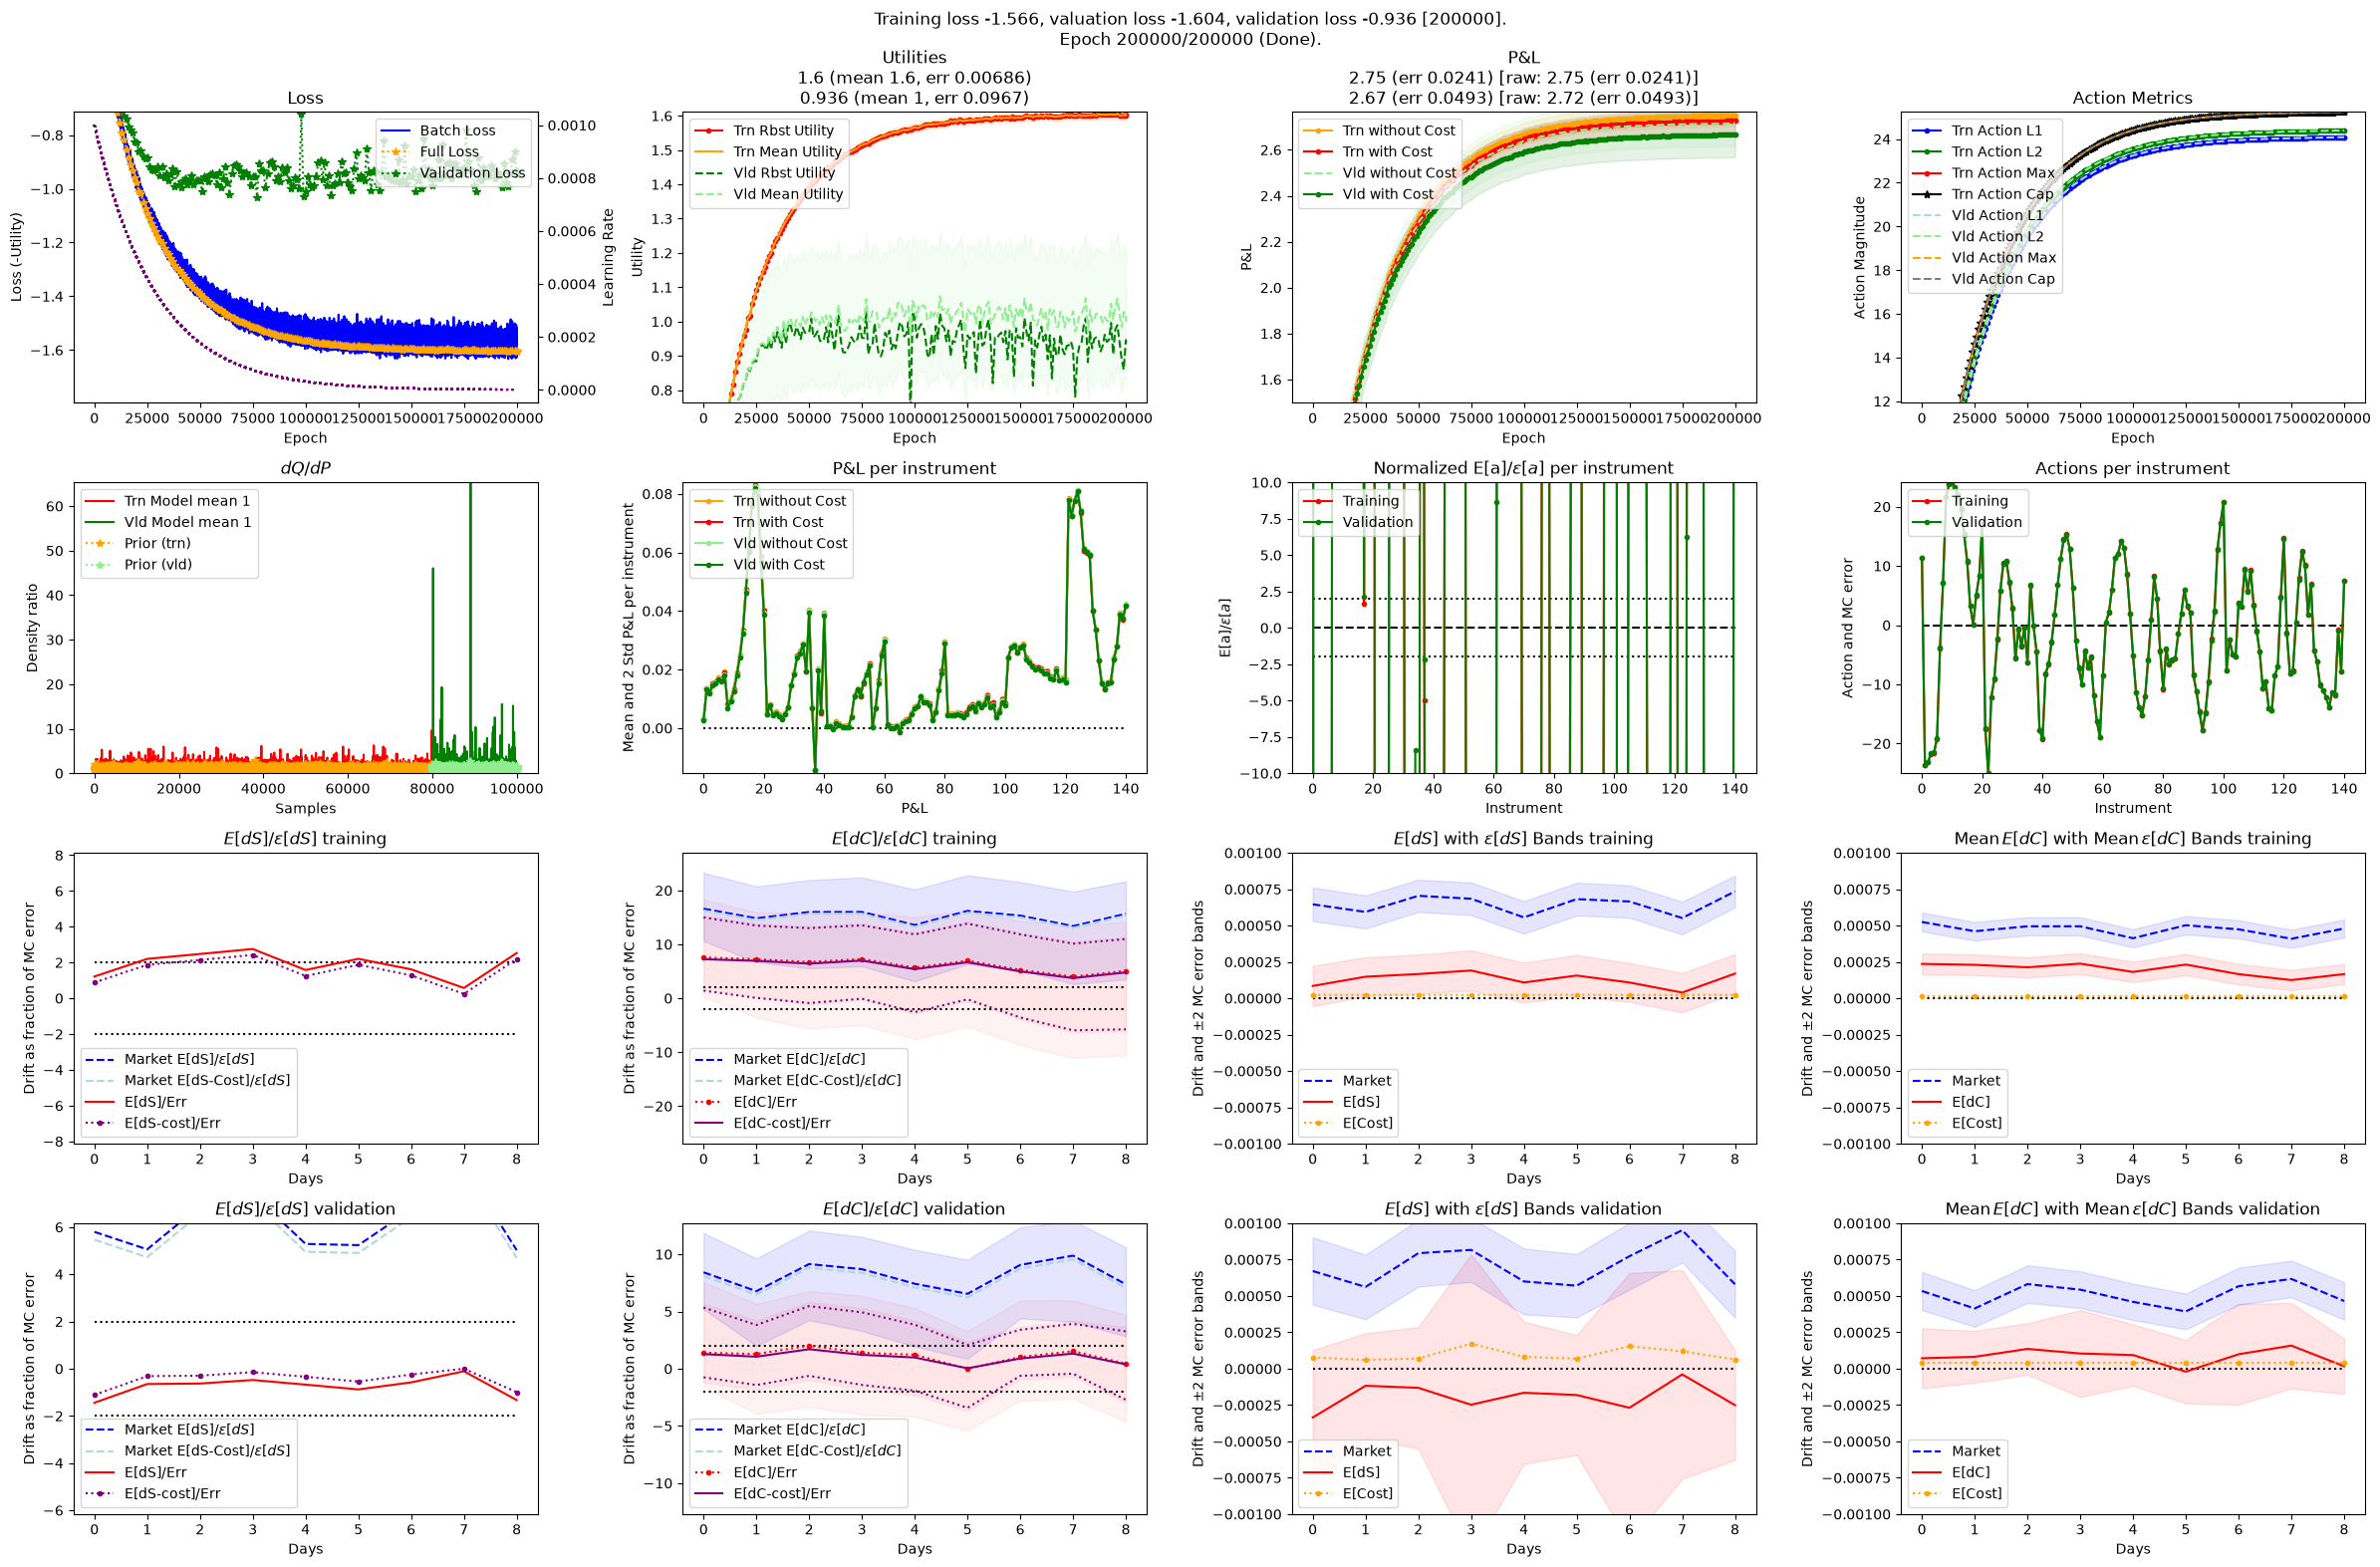

00: Training drn,outer,cost=std,u=pexp,rndboot,delthdg,batched_v2@dysanosV2 0.51 with epochs=200000,lr=0.001->1e-06,wdec=0.0001,bsize=20000,vbsize=all,pcnt_val=0.20,compile=True,epoch_interval=1000,time_interval=120.0s on Env(prec=32,device=cuda:2,debug=False):
00: Model trained for 200000 epochs. This took 49:47.                                                                                                        
01:   Model checkpoint file is'/home/hans/.dysanos_dhx/dysanosV2/drn,outer,cost=std,u=pexp,rndboot,delth 0e18ff81.pt'.
01:   Writing model output to '/home/hans/.dysanos_dhx/dysanosV2/drn,outer,cost=std,u=pexp,rndboot,delth 0e18ff81.mo'... done; this took 5.4ms.
00: Model drn,outer,cost=std,u=pexp,rndboot,delthdg,batched_v2 version 0.51 group 'dysanosV2' trained for 200000 epochs. Final training loss: -1.566, valuation loss: -1.604, validation loss: -0.936. This took 5.76ms.


In [3]:
from quantdata.dysanos.grid.torch_drift_changeV2 import DRNConfig, _notebook_name, train, TrainConfig, VizDRNConfig, BaseEnvironment, Context
import torch as torch
import numpy as np
from quantdata.torch.ffw import FeedForwardConfig
from quantdata.torch import DeviceLock

mdl_config = DRNConfig( 
    label=_notebook_name(),
    group="dysanosV2", 
    user_version="0.51",
    utility="powexp", 
    lmbda=1.0, 
    delta_hedged=True, 
    cost = 0.00, # 1 bps
    cost_std = 1.,
    pf_config=FeedForwardConfig(
        num_depth = 2,
        num_width = 100,
        activation = "LeakyReLU",
        use_bias = True
    ),
    action_cap = 0.1,
    learn_action_cap = True,
    boot_strap = 100,
    boot_mode = "outer",
    block_size = None,
    boot_random = True,
    cash_trades = True
)


import gc
model_RN_output = 0
gc.collect()
print(torch.cuda.memory_allocated() / 1024**3, "GiB allocated")
print(torch.cuda.memory_reserved() / 1024**3, "GiB reserved")

def run():
    trn_config = TrainConfig( num_epochs=200_000, 
                              pcnt_validation=0.2,
                              lr=1E-3, final_lr=1E-6, weight_decay=1E-4, batch_size=20_000, compile=True, epoch_interval=1000 )
    viz_config = VizDRNConfig()

    with DeviceLock() as device_lock:
        model_RN   = train(
                        ex.universe,
                        ref_dQdP=ex.dQdP_dS,
                        mdl_config=mdl_config, 
                        trn_config=trn_config, 
                        viz_config=viz_config, restart=False, just_load="no",
                        env=BaseEnvironment(device=device_lock.device, debug=False), verbose=Context.all )
        gc.collect()

    return model_RN

model_RN_output = run()
